### 

# Technical Assignment - VICTOR FERNANDEZ OLIVERAS

## Root Cause Analysis

### 0. Load packages, Access data & Clean format

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
# Access data
path = "fragrance_stability_dataset_corrupted_20260601_161558.csv"
df = pd.read_csv(path)

# Data quality problems #

# Temperature column name
df.rename(columns={'temp_value': 'reaction_temperature_celsius'}, inplace=True)

# Transform farenheits to celsius
df.loc[df['temp_unit'] == 'F', 'reaction_temperature_celsius'] = (df.loc[df['temp_unit'] == 'F', 'reaction_temperature_celsius'] - 32) * 5.0/9.0
df.loc[df['temp_unit'] == 'F', 'temp_unit'] = 'C'

# Unify the mixed timestamp formats in this dataset.
raw_timestamp = df["event_timestamp"].astype("string").str.strip()

df["timestamp_time_missing"] = ( # True if no hour info
    raw_timestamp.notna()
    & ~raw_timestamp.str.contains(
        r"\d{1,2}:\d{2}(?::\d{2})?",
        regex=True,
        na=False,
    )
)

df["event_timestamp"] = pd.to_datetime(raw_timestamp, format="mixed", dayfirst=False, errors="coerce")

# Date-only values have no known time; do not represent them as midnight (default 00:00:00).
df.loc[df["timestamp_time_missing"], "event_timestamp"] = pd.NaT

In [20]:
# Check the plant locations, countries and reactors. 
df.groupby(['plant_location', 'plant_country', 'production_line_id']).size().reset_index(name='count').sort_values(
    by=['plant_country', 'plant_location', 'production_line_id'],
    ascending=[True, True, True]
)

,plant_location,plant_country,production_line_id,count
0,Plant-01,Country-01,Fragrance-Synthesis-Reactor-01,5598
1,Plant-01,Country-01,Fragrance-Synthesis-Reactor-02,6140
2,Plant-01,Country-01,Fragrance-Synthesis-Reactor-03,6122
3,Plant-01,Country-01,Fragrance-Synthesis-Reactor-04,7070
4,Plant-01,Country-01,Fragrance-Synthesis-Reactor-05,6950
5,Plant-01,Country-01,Fragrance-Synthesis-Reactor-06,7015
6,Plant-01,Country-01,Fragrance-Synthesis-Reactor-07,7658
7,Plant-01,Country-01,Fragrance-Synthesis-Reactor-08,7840
8,Plant-01,Country-01,Fragrance-Synthesis-Reactor-09,8104
9,Plant-01,Country-01,Fragrance-Synthesis-Reactor-10,8147


### 1. Data Distributions

In [21]:
# Normal ranges for each measure.
# True if can be negative, False if cannot be negative.
normal_ranges = {
    'reaction_temperature_celsius': ((75, 100), True),
    'vessel_pressure_bar': ((2, 3), False),
    'refractive_index': ((1.43, 1.49), True),
    'density_g_cm3': ((0.80, 0.90), True),
    'ph_level': ((5.0, 6.0), True),
    'mixing_torque_nm': ((9.0, 12.5), False),
    'mass_flow_rate_kg_h': ((380, 520), False),
    'stability_months': ((18, 30), True)
}

In [22]:
# Generate a flag column for each measure indicating wether the value is within the normal range. 
for measure, info in normal_ranges.items():
    lower, upper = info[0]
    df[f'{measure}_in_range'] = df[measure].apply(lambda x: lower <= x <= upper if not pd.isnull(x) else False) # create the flag column

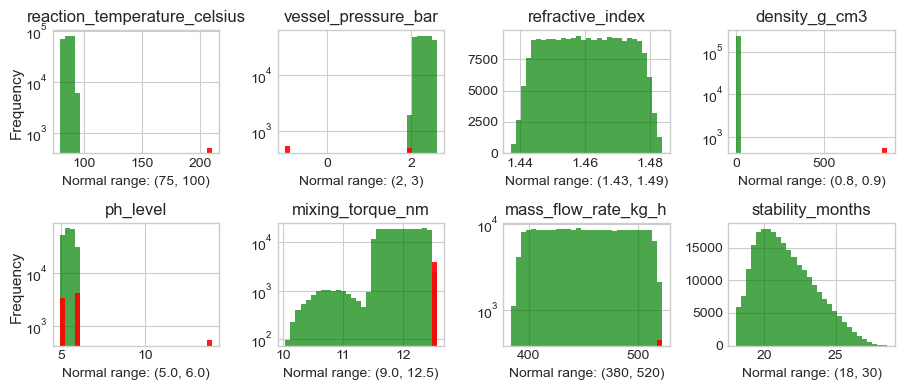

In [23]:
# Multidigure
fig, axes = plt.subplots(2, 4, figsize=(9, 4))
axes = axes.flatten()

for ax, measure in zip(axes, normal_ranges):

    normal_range = normal_ranges[measure][0]

    data = df[[measure, f'{measure}_in_range']].dropna() # Drop NaN to enable plotting

    bins = np.histogram_bin_edges(data[measure], bins=30)

    # In the normal range
    ax.hist(
        data.loc[data[f'{measure}_in_range'], measure], 
        bins=bins, color='green', alpha = 0.7)
    
    # Out of the normal range
    ax.hist(
        data.loc[~data[f'{measure}_in_range'], measure],
        bins=bins, color='red', alpha = 0.9)

    # Formatting
    ax.set_title(measure, fontsize=12)
    ax.set_xlabel(f'Normal range: {normal_range}', fontsize=10)

    # For clearer visualization
    if measure == "stability_months" or measure == "refractive_index":
        continue
    else: 
        ax.set_yscale('log')

# Shared Y-axis labels 
fig.text(0, 0.73, 'Frequency', va='center', rotation='vertical', fontsize=11)
fig.text(0, 0.27, 'Frequency', va='center', rotation='vertical', fontsize=11)

plt.tight_layout()

# Save and show
plt.savefig('plots/root_cause/feature_distributions.png', dpi=300)
plt.show()

### 2. Differences Between Plants and Reactors

#### 2.1 Plants (Countries)

C:\Users\vicfo\AppData\Local\Temp\ipykernel_154072\4159400408.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([country.replace('Country-', '') for country in countries])
C:\Users\vicfo\AppData\Local\Temp\ipykernel_154072\4159400408.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([country.replace('Country-', '') for country in countries])
C:\Users\vicfo\AppData\Local\Temp\ipykernel_154072\4159400408.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([country.replace('Country-', '') for country in countries])
C:\Users\vicfo\AppData\Local\Temp\ipykernel_154072\4159400408.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ti

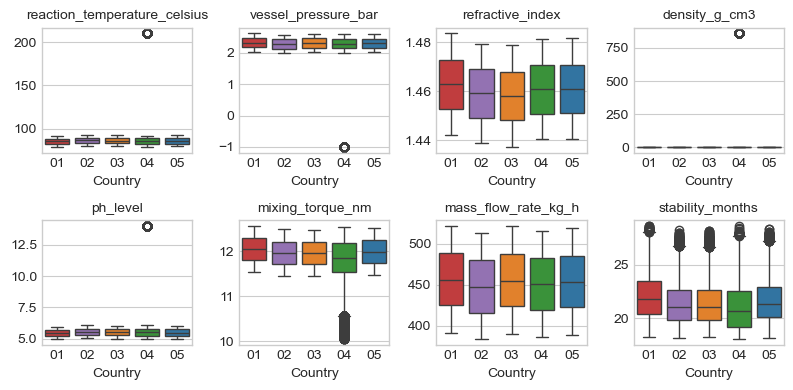

In [24]:
# List of distinct countries
countries = sorted(df['plant_country'].dropna().unique())
numeric_cols = list(normal_ranges.keys())

# Figure settings
fig, axes = plt.subplots(2, 4, figsize=(8, 4))
axes = axes.flatten()

# Boxplots for each production measure, by country
for ax, feature in zip(axes, numeric_cols):
    
    # Values
    sns.boxplot(data=df, x='plant_country', y=feature, hue='plant_country', order=countries, palette='tab10', legend=False, ax=ax)

    # Settings
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel('Country')
    ax.set_xticklabels([country.replace('Country-', '') for country in countries])
    ax.set_ylabel('') # Better visualization

# Hide unused subplot
for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)

# Save and show
plt.tight_layout()
plt.savefig('plots/root_cause/boxplots_by_country.png', dpi=300)
plt.show()

#### 2.2 Reactors

In [25]:
# Country to plot
selected_country = 'Country-04'

C:\Users\vicfo\AppData\Local\Temp\ipykernel_154072\3431581251.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([
C:\Users\vicfo\AppData\Local\Temp\ipykernel_154072\3431581251.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([
C:\Users\vicfo\AppData\Local\Temp\ipykernel_154072\3431581251.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([
C:\Users\vicfo\AppData\Local\Temp\ipykernel_154072\3431581251.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([
C:\Users\vicfo\AppData\Local\Temp\ipykernel_154072\3431581251.py:26: UserWarning: set_ticklabels() should only be used w

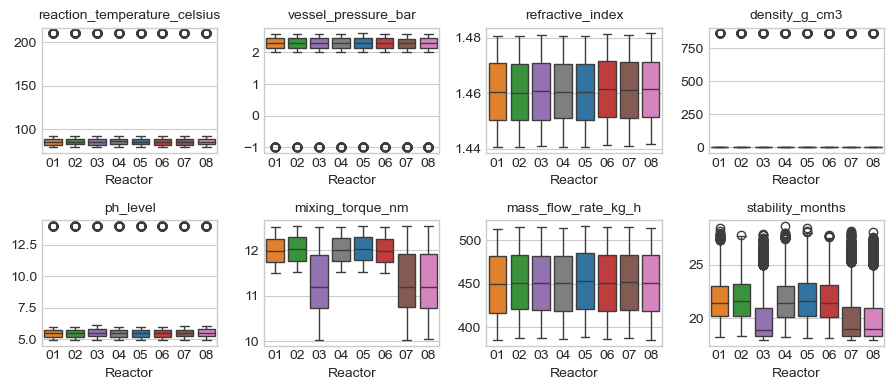

In [26]:
# Same idea/code but for reactos, basically
country_df = df[df['plant_country'] == selected_country]

production_line_ids = sorted(country_df['production_line_id'].unique())

fig, axes = plt.subplots(2, 4, figsize=(9, 4))
axes = axes.flatten()

for ax, feature in zip(axes, numeric_cols):

    sns.boxplot(
        data=country_df,
        x='production_line_id',
        y=feature,
        hue='production_line_id',
        palette='tab10',
        legend=False,
        order=production_line_ids,
        ax=ax
    )

    ax.set_xlabel('Reactor')
    ax.set_title(feature, fontsize=10)
    ax.set_ylabel('') # Better visualization

    ax.set_xticklabels([
        p.replace("Fragrance-Synthesis-Reactor-", '')
        for p in production_line_ids
    ])

for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(f'plots/root_cause/boxplots_by_reactor_{selected_country}.png', dpi=300)
plt.show()

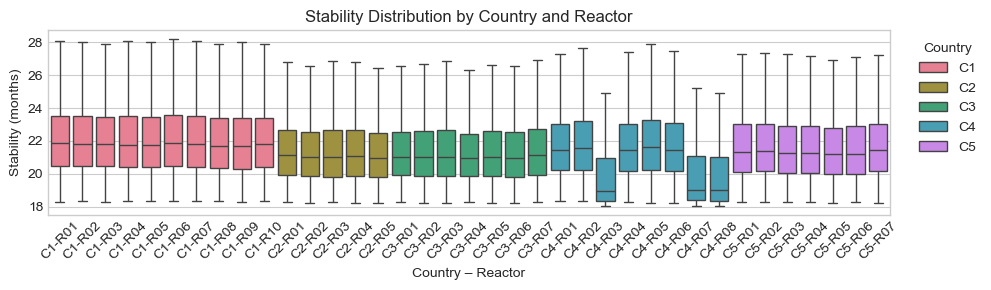

In [27]:
# Differences in stability across all the countries and reactors together.
plot_df = df.copy()

# Short numeric labeling for visualization
plot_df['country'] = plot_df['plant_country'].str.extract(r'(\d+)').astype(int) # extracts only the numbers
plot_df['reactor'] = plot_df['production_line_id'].str.extract(r'(\d+)').astype(int)
plot_df['country_reactor'] = ('C' + plot_df['country'].astype(str) + '-R' + plot_df['reactor'].astype(str).str.zfill(2))
plot_df['country_label'] = 'C' + plot_df['country'].astype(str)
order = (plot_df[['country', 'reactor', 'country_reactor']].drop_duplicates().sort_values(['country', 'reactor'])['country_reactor'].tolist()) # Order by country and then by reactor

# One color for each country
country_labels = sorted(plot_df['country_label'].unique())
colors = sns.color_palette('husl', n_colors=len(country_labels))
palette = dict(zip(country_labels, colors))

# Plot #
fig, ax = plt.subplots(figsize=(10, 3))

sns.boxplot(data=plot_df, x='country_reactor', y='stability_months', order=order, hue='country_label', palette=palette, dodge=False, showfliers=False, ax=ax)

# formatting
ax.set_xlabel('Country – Reactor')
ax.set_ylabel('Stability (months)')
ax.set_title('Stability Distribution by Country and Reactor')
ax.tick_params(axis='x', rotation=45)

# Legend sorted by country
handles, labels = ax.get_legend_handles_labels()
sorted_legend = sorted(zip(handles, labels), key=lambda x: int(x[1].replace('C', '')))
handles, labels = zip(*sorted_legend)
ax.legend(handles, labels, title='Country', bbox_to_anchor=(1.02, 1), loc='upper left')

# Save and show
plt.tight_layout()
plt.savefig('plots/root_cause/stability_distribution_by_country_reactor.png', dpi=300, bbox_inches='tight')
plt.show()

### 3. Correlation Analysis

In [28]:
correlations = (
    df[numeric_cols]
    .corr()['stability_months']
    .drop('stability_months')  # I don't want the correlation of stability with itself
    .sort_values()
)

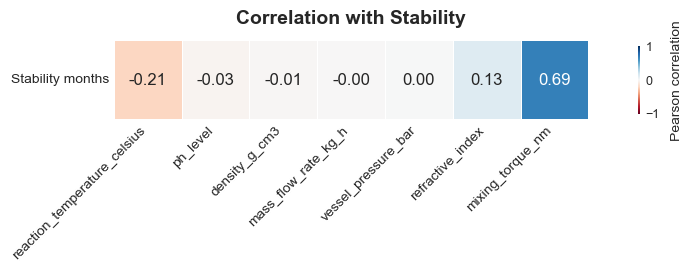

In [29]:
# Convert into a matrix
corr_matrix = correlations.to_frame().T
corr_matrix.columns = correlations.index

# Heatmap
fig, ax = plt.subplots(figsize=(7.5, 2.8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 12},
    cbar_kws={
        'label': 'Pearson correlation',
        'shrink': 0.85,
        'pad': 0.08,
        'aspect': 25
    },
    ax=ax
)

# Formatting
ax.set_title('Correlation with Stability', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticklabels(ax.get_xticklabels(), fontsize=10, rotation=45, ha='right')
ax.set_yticklabels(['Stability months'], fontsize=10, rotation=0)

# Legend
colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=9)
colorbar.set_label('Pearson correlation', fontsize=10, labelpad=8)

# Save and show
plt.tight_layout(pad=1.0)
plt.savefig("plots/root_cause/correlation_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

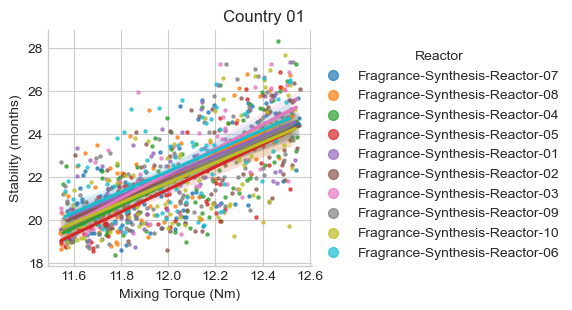

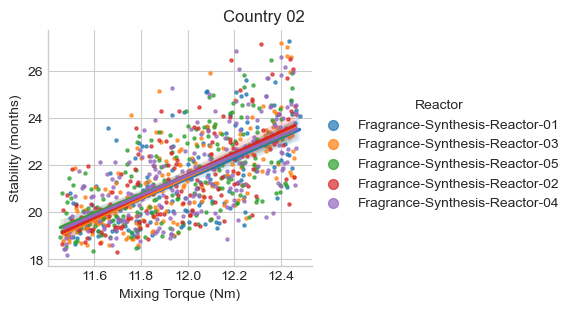

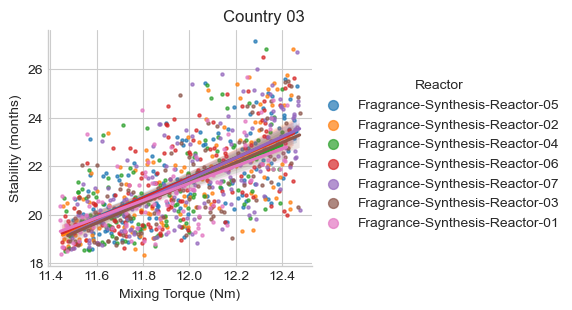

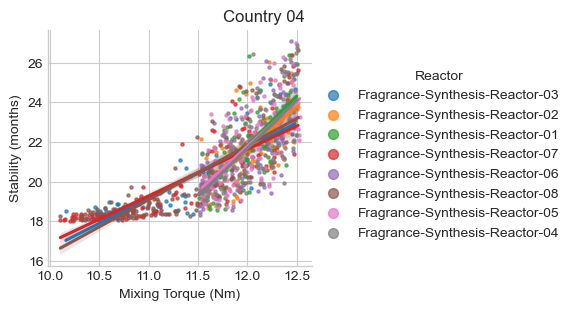

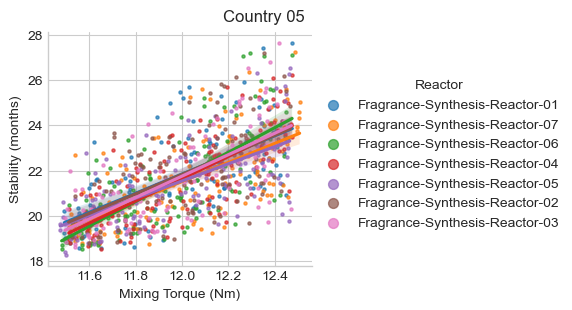

In [30]:
# Inspection of correaltions across countries. 
for country in sorted(df['plant_country'].unique()):

    data = df[df['plant_country'] == country].sample(1000) # There are too many data points, so I sample 1000 for better visualization.

    # Correlation plot
    g = sns.lmplot(data=data, x='mixing_torque_nm', y='stability_months', hue='production_line_id', height=3, aspect=1.2, scatter_kws={'s': 5, 'alpha': 0.7})

    # Formatting
    g.set_axis_labels('Mixing Torque (Nm)', 'Stability (months)')
    g.figure.suptitle(country.replace('Country-', 'Country '), y=1.02)
    g._legend.set_title('Reactor')
    for handle in g._legend.legend_handles: # Bigger legend dots for visualization
        handle.set_sizes([50])

    # Save and show
    g.savefig(f'plots/root_cause/mixing_torque_vs_stability_{country}.png', dpi=300)
    plt.show()

### 4. Final Checks

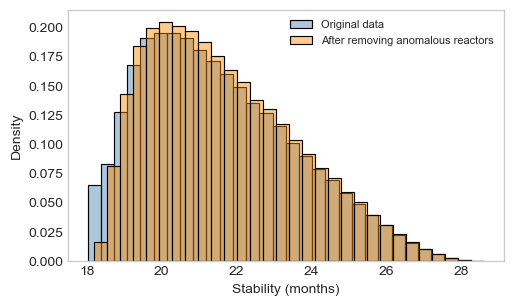

In [31]:
# Remove only Reactors 3, 7, and 8 from Country-04
reactors_to_remove = ['Fragrance-Synthesis-Reactor-03', 'Fragrance-Synthesis-Reactor-07', 'Fragrance-Synthesis-Reactor-08']
df_clean = df[~((df['plant_country'] == 'Country-04') & (df['production_line_id'].isin(reactors_to_remove)))].copy()

# Plot #
fig, ax = plt.subplots(figsize=(5, 3))

sns.histplot(data=df, x='stability_months', bins=30, stat='density', color='steelblue', alpha=0.45, kde=False, label='Original data', ax=ax)
sns.histplot(data=df_clean, x='stability_months', bins=30, stat='density', color='darkorange', alpha=0.45, kde=False, label='After removing anomalous reactors', ax=ax)

# Formatting
ax.set(xlabel='Stability (months)', ylabel='Density')
ax.legend(fontsize=8, frameon=False)
ax.grid(False)

# Save and show
plt.savefig('plots/root_cause/stability_distribution_comparison.png', dpi=300, bbox_inches='tight')

plt.tight_layout(pad=0.5)
plt.show()

In [32]:
stability_range_by_risk = (df.groupby('oxidation_risk_flag')['stability_months'] .agg(['count', 'min', 'max']))
stability_range_by_risk_clean = (df_clean.groupby('oxidation_risk_flag')['stability_months'] .agg(['count', 'min', 'max']))

# calculate the difference in the % of rows with a True in their oxidation_risk_flag
proportion_oxidation_general = (stability_range_by_risk['count'].iloc[1] / stability_range_by_risk['count'].sum()) * 100
proportion_oxidation_clean = (stability_range_by_risk_clean['count'].iloc[1] / stability_range_by_risk_clean['count'].sum()) * 100
diff = (proportion_oxidation_general - proportion_oxidation_clean)
print(f'Reduction in proportion of oxidation risk: {round(diff, 2)} %')

# And the mean stability for each group
mean_stability_general = df['stability_months'].mean()
mean_stability_clean = df_clean['stability_months'].mean()
diff = (mean_stability_clean - mean_stability_general)
print(f'Increase in mean stability: {round(diff, 2)} months')

Reduction in proportion of oxidation risk: 2.73 %
Increase in mean stability: 0.15 months


In [34]:
stability_range_by_risk.head()

,count,min,max
oxidation_risk_flag,,,
False,140183,21.000034,28.609162
True,119017,18.015190,20.999955


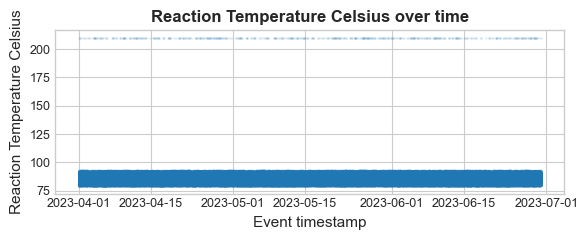

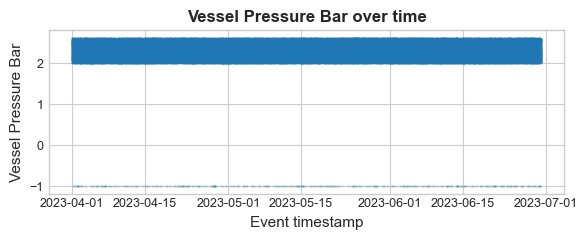

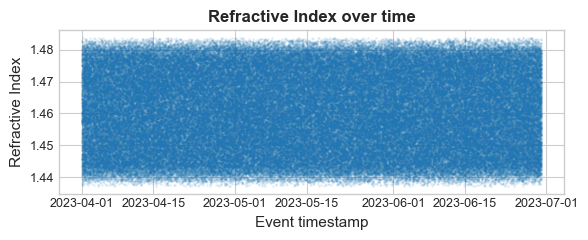

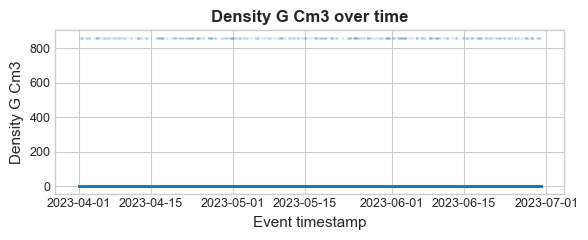

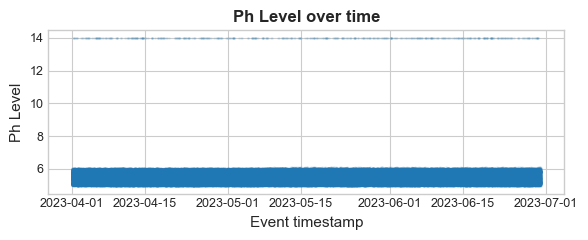

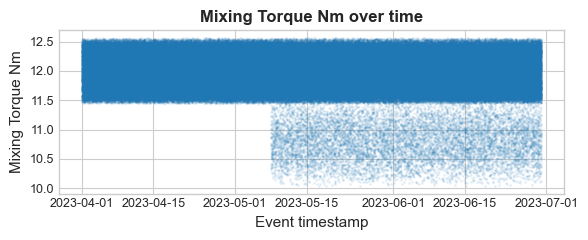

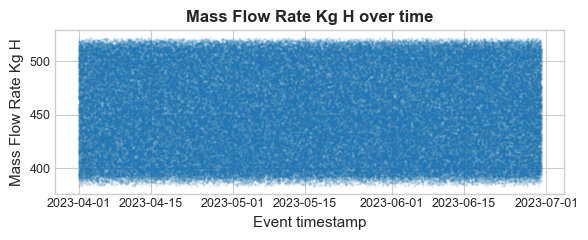

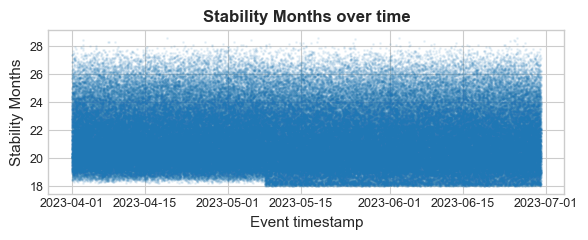

In [ ]:
# Pot each feature over time
for col in numeric_cols:
    plot_df = df[["event_timestamp", col]].dropna().sort_values("event_timestamp")

    clean_title = col.replace("_", " ").title()

    # Plot#
    plt.figure(figsize=(6, 2.5))
    plt.plot(plot_df["event_timestamp"], plot_df[col], ".", markersize=2, alpha=0.08)

    # Settings
    plt.xlabel("Event timestamp", fontsize=11)
    plt.ylabel(clean_title, fontsize=11)
    plt.title(f"{clean_title} over time", fontsize=12, fontweight="bold")
    plt.tick_params(axis="both", labelsize=9)
    plt.tight_layout()

    # Save and show
    plt.savefig(f"plots/root_cause/{col}_over_time.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

## Predictive Model

### 0. Load Packages, Access data

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
import shap

In [21]:
dff = df.copy()  # Create a copy of the original DataFrame to avoid modifying it directly

# Prepare data
features = numeric_cols.copy()
features.remove('stability_months')  # Exclude the target variable

# Remove batches without stability data. 
dff[dff['stability_months'].notnull()]

# Fill null values with the columns' mean. Ideally, I would delete them, but I would lose too much data. 
dff[features] = dff[features].fillna(dff[features].mean())

### 1. Splitting

In [22]:
X = dff[features]
y = dff['stability_months']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")

Training set: (207360, 7)
Test set:     (51840, 7)


### 2. Baseline Model

In [42]:
# Use only mixing torque
X_train_torque = X_train[['mixing_torque_nm']]
X_test_torque = X_test[['mixing_torque_nm']]

# Fit the model
torque_model = LinearRegression()
torque_model.fit(X_train_torque, y_train)

# Use it to predict the stablity
y_pred_torque = torque_model.predict(X_test_torque)

# Evaluate error
mae = mean_absolute_error(y_test, y_pred_torque)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_torque))
r2 = r2_score(y_test, y_pred_torque)

print(f"Torque-only MAE:  {mae:.3f} months")
print(f"Torque-only RMSE: {rmse:.3f} months")
print(f"Torque-only R²:   {r2:.3f}")

print(f"Equation: stability = {torque_model.coef_[0]:.3f} × torque + {torque_model.intercept_:.3f}")

Torque-only MAE:  1.248 months
Torque-only RMSE: 1.538 months
Torque-only R²:   0.434
Equation: stability = 3.580 × torque + -21.222


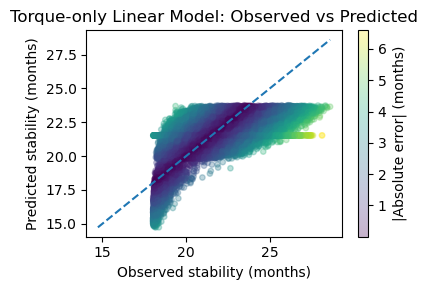

In [24]:
# Absolute prediction error
abs_error = np.abs(y_test.values - y_pred_torque)

plt.figure(figsize=(4, 3))

# Scatter colored by absolute error
scat = plt.scatter(y_test, y_pred_torque, c=abs_error, cmap='viridis', alpha=0.3, s=15)

# Perfect prediction line
min_val = min(y_test.min(), y_pred_torque.min())
max_val = max(y_test.max(), y_pred_torque.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', linewidth=1.5)

# Colorbar for error magnitude
cbar = plt.colorbar(scat)
cbar.set_label('|Absolute error| (months)')

plt.xlabel('Observed stability (months)')
plt.ylabel('Predicted stability (months)')
plt.title('Torque-only Linear Model: Observed vs Predicted')
plt.tight_layout()

# Save athe plot and show it
plt.savefig('plots/predictive_model/baseline_observed_vs_predicted.png', dpi=300)
plt.show()

### 3. Linear Regression

In [43]:
# Train the linear model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions with the trained model
y_pred = model.predict(X_test)

# Evaluation (errors)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Linear Regression MAE:  {mae:.3f} months")
print(f"Linear Regression RMSE: {rmse:.3f} months")
print(f"Linear Regression R²:   {r2:.3f}")

Linear Regression MAE:  1.169 months
Linear Regression RMSE: 1.466 months
Linear Regression R²:   0.486


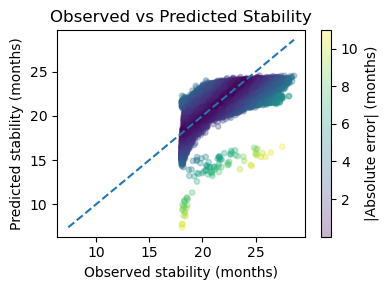

In [28]:
# Absolute prediction error
abs_error = np.abs(y_test.values - y_pred)

# Plot #
plt.figure(figsize=(4, 3))

# Scatter colored by absolute error
scat = plt.scatter(y_test, y_pred, c=abs_error, cmap='viridis', alpha=0.3, s=15)

# Perfect prediction line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', linewidth=1.5)

# Colorbar for error magnitude
cbar = plt.colorbar(scat)
cbar.set_label('|Absolute error| (months)')

plt.xlabel('Observed stability (months)')
plt.ylabel('Predicted stability (months)')
plt.title('Observed vs Predicted Stability')

plt.tight_layout()

# Save and show
plt.savefig('plots/predictive_model/linear_regression_observed_vs_predicted.png', dpi=300)
plt.show()

### 4. Random Forest

In [29]:
# Intialize random forest regressor
rf = RandomForestRegressor(random_state=42, n_jobs=-1)

# Hyperparameter space search
param_distributions = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 4],
    'max_features': [1.0, 'sqrt']
}

search = RandomizedSearchCV(
    rf,
    param_distributions=param_distributions,
    n_iter=8, # number of combinations of hyperparams
    scoring='neg_mean_absolute_error',
    cv=2, # train/val folds
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Perform hyperparam optimization and extract the best model
search.fit(X_train, y_train)
best_rf = search.best_estimator_
print("Best parameters:")
print(search.best_params_)

Fitting 2 folds for each of 8 candidates, totalling 16 fits
Best parameters:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 1.0, 'max_depth': None}


In [44]:
# Use the best model to predict the test data
y_pred_rf = best_rf.predict(X_test)

# Calculate and show errors
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)

print(f"Random Forest MAE:  {mae:.3f} months")
print(f"Random Forest RMSE: {rmse:.3f} months")
print(f"Random Forest R²:   {r2:.3f}")

Random Forest MAE:  0.787 months
Random Forest RMSE: 1.018 months
Random Forest R²:   0.752


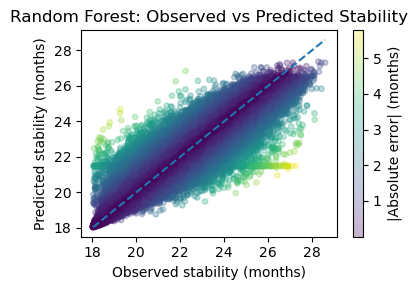

In [31]:
# Absolute prediction error
abs_error = np.abs(y_test.values - y_pred_rf)

# PLot #
plt.figure(figsize=(4, 3))

# Scatter
scat = plt.scatter(y_test, y_pred_rf, c=abs_error, cmap='viridis', alpha=0.3, s=15)

# Perfect prediction line
min_val = min(y_test.min(), y_pred_rf.min())
max_val = max(y_test.max(), y_pred_rf.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', linewidth=1.5)

# Colorbar/legebd for error 
cbar = plt.colorbar(scat)
cbar.set_label('|Absolute error| (months)')

# Labels
plt.xlabel('Observed stability (months)')
plt.ylabel('Predicted stability (months)')
plt.title('Random Forest: Observed vs Predicted Stability')

plt.tight_layout()

# Save and show
plt.savefig('plots/predictive_model/random_forest_observed_vs_predicted.png', dpi=300)
plt.show()

### 5. XGBoost

#### 5.1 Model Architecture and Training

In [32]:
# Define the XGBoost regressor
xgb = XGBRegressor(objective='reg:squarederror', random_state=42)

# Hyperparameter options
hyparams = {
    'n_estimators': [100, 200, 300], # number of decision trees
    'max_depth': [3, 5, 7], # depth of each tree
    'learning_rate': [0.03, 0.05, 0.1], # influence of individual trees
    'subsample': [0.8, 1.0], # % of data fitted in each tree
    'colsample_bytree': [0.8, 1.0] # % of features used in each tree
}

# Fit the model using diverse hyperaparameter combinations
search_xgb = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=hyparams,
    n_iter=10, # number of hyperparams combinations
    scoring='neg_mean_absolute_error', # neg to minimize error
    cv=2, # train/val folds
    random_state=42,
    verbose=1 # to show the number of options we are considering
)

# Fit the model and show th best hyperparams
search_xgb.fit(X_train, y_train)
best_xgb = search_xgb.best_estimator_

print("Best parameters:")
print(search_xgb.best_params_)

Fitting 2 folds for each of 10 candidates, totalling 20 fits
Best parameters:
{'subsample': 1.0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


#### 5.2 Testing

In [33]:
# Use the best model (fitted) to predict the test data
y_pred_xgb = best_xgb.predict(X_test)

# Calculate the error
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2 = r2_score(y_test, y_pred_xgb)

# And show it
print(f"XGBoost MAE:  {mae:.3f} months")
print(f"XGBoost RMSE: {rmse:.3f} months")
print(f"XGBoost R²:   {r2:.3f}")

XGBoost MAE:  0.762 months
XGBoost RMSE: 0.978 months
XGBoost R²:   0.771


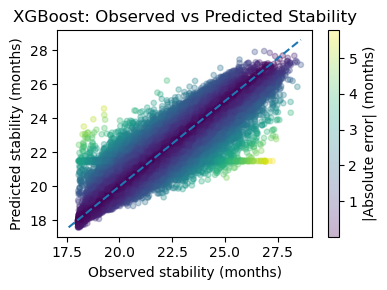

In [34]:
# Absolute prediction error
abs_error = np.abs(y_test.values - y_pred_xgb)

plt.figure(figsize=(4, 3))

# Scatter colored by absolute error
scat = plt.scatter(y_test, y_pred_xgb, c=abs_error, cmap='viridis', alpha=0.3, s=15)

# Perfect prediction line
min_val = min(y_test.min(), y_pred_xgb.min())
max_val = max(y_test.max(), y_pred_xgb.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', linewidth=1.5)

# Colorbar for error magnitude
cbar = plt.colorbar(scat)
cbar.set_label('|Absolute error| (months)')

# Labels
plt.xlabel('Observed stability (months)')
plt.ylabel('Predicted stability (months)')
plt.title('XGBoost: Observed vs Predicted Stability')
plt.tight_layout()

# Save and show
plt.savefig('plots/predictive_model/xgboost_observed_vs_predicted.png', dpi=300)
plt.show()

#### 5.3 Prediction Condifence

In [35]:
# 5th Percentile
xgb_lower = XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.05,
    n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1
)

# 95th Percentile
xgb_upper = XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.95,
    n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1
)

# Fit the models 
xgb_lower.fit(X_train, y_train)
xgb_upper.fit(X_train, y_train)

# Use the model to predict the 5th and 95th percentiles of the test set's batches
y_lower = xgb_lower.predict(X_test)
y_upper = xgb_upper.predict(X_test)

In [36]:
# Check correct calibration
coverage = np.mean((y_test >= y_lower) & (y_test <= y_upper))
print(f"90% prediction interval coverage: {coverage*100:.2f}%") # real % of predicted values that fall inside the predicted interval

# Interval width
interval_width = y_upper - y_lower
print(f"Mean interval width: {interval_width.mean():.2f} months")

90% prediction interval coverage: 89.82%
Mean interval width: 2.98 months


#### 5.4 Interpretability

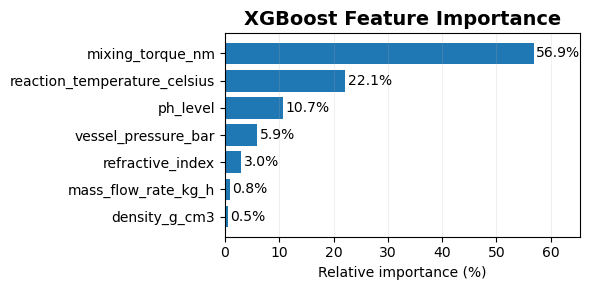

In [39]:
# Feature Importance Scores
importance = pd.DataFrame({'feature': X_train.columns, 'importance': best_xgb.feature_importances_}).sort_values('importance', ascending=False)
importance['importance_pct'] = (importance['importance'] / importance['importance'].sum() * 100)

# Plot #
plt.figure(figsize=(6, 3))

bars = plt.barh(importance['feature'], importance['importance_pct'])

# Formatting
plt.xlabel('Relative importance (%)')
plt.ylabel('')
plt.title('XGBoost Feature Importance', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.xlim(0, importance['importance_pct'].max() * 1.15)

# Add percentages
for bar, value in zip(bars, importance['importance_pct']):
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, f'{value:.1f}%', va='center', fontsize=10)

# Final settings
plt.grid(axis='x', alpha=0.2)
plt.tight_layout()

# SAve and show
plt.savefig('plots/predictive_model/xgboost_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

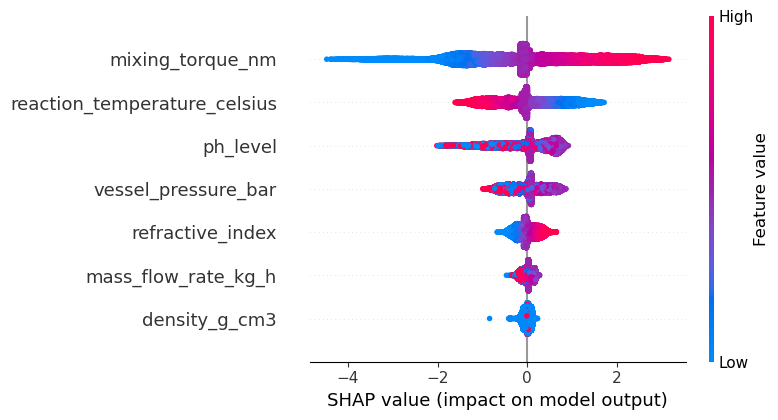

<Figure size 640x480 with 0 Axes>

In [ ]:
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer(X_test)

# Figure #
plt.figure(figsize=(7, 4.5))

shap.summary_plot(shap_values, X_test, plot_type='bar', max_display=7, show=False)

# Formatting
plt.title('XGBoost Feature Importance', fontsize=13, fontweight='bold')
plt.xlabel('Mean |SHAP value|')
plt.tight_layout()

# Save the figure
plt.savefig('plots/predictive_model/xgboost_shap_importance.png', dpi=300, bbox_inches='tight')

# And show it
plt.show()